<a href="https://colab.research.google.com/github/ryanglenc/MAT_442/blob/main/442_HW_3_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.svm import SVC
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

## 3.5 K-means

Given data points x₁, ..., xₘ and a number of clusters k, K-means looks for cluster centers μ₁, ..., μₖ and an assignment of each point to a cluster that minimize the **within-cluster sum of squares** (also called inertia):

J = Σᵢ ‖xᵢ − μ_c(i)‖²,  where c(i) is the cluster assigned to point i.

This problem is non-convex and hard to solve exactly, so we use **Lloyd's algorithm**, which alternates two steps:

1. **Assignment step:** assign each point to its nearest center.
2. **Update step:** move each center to the mean of the points assigned to it.

Each step can only decrease J (or leave it unchanged), so J decreases monotonically and the algorithm stops when the centers stop moving. But because J is non-convex, the result can depend on the starting centers.

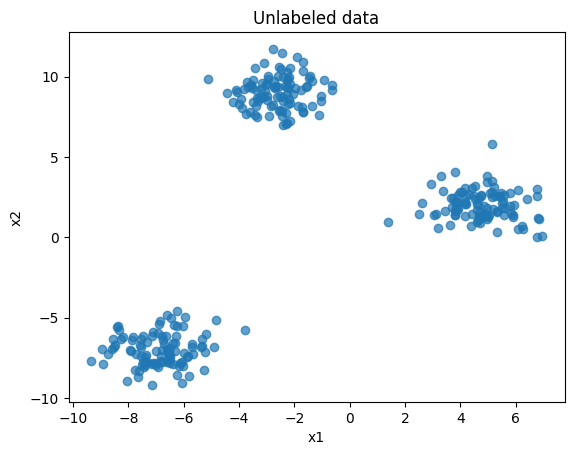

In [11]:
X, true_labels = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

plt.scatter(X[:, 0], X[:, 1], alpha=0.7)
plt.title('Unlabeled data')
plt.xlabel('x1'); plt.ylabel('x2')
plt.show()

Converged after 10 iterations
Final centers:
 [[-6.1628 -6.7537]
 [-7.7652 -7.2655]
 [ 1.0569  5.5271]]
Final inertia J: 5693.4281856728985
Inertia never increases: True


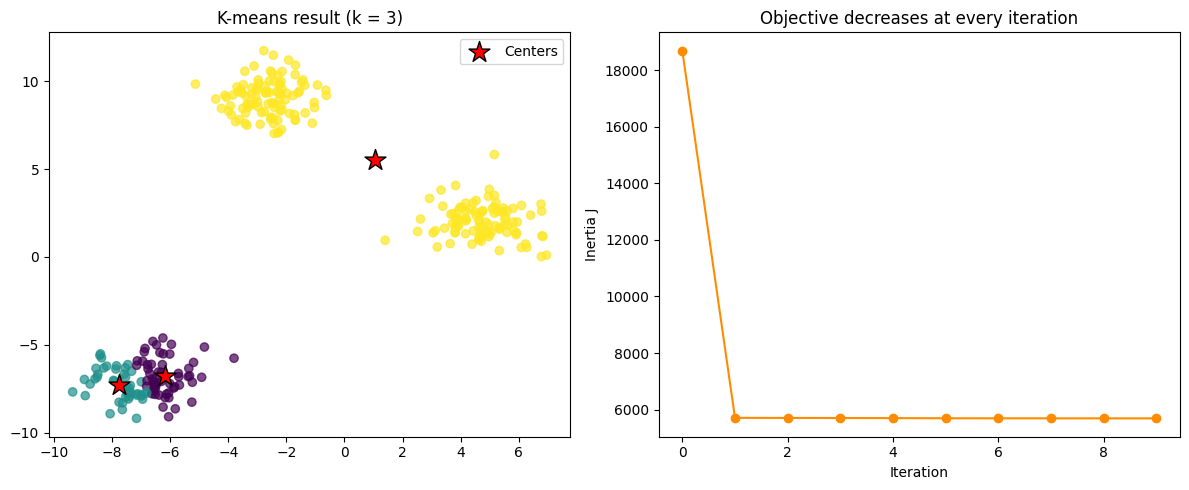

In [12]:
def kmeans(X, k, seed=0, max_iter=100):
    """Lloyd's algorithm. Returns centers, labels, and the inertia at each iteration."""
    r = np.random.default_rng(seed)
    centers = X[r.choice(len(X), size=k, replace=False)]   # random points as initial centers
    inertias = []
    for _ in range(max_iter):
        # Assignment step: nearest center for each point
        dist = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
        labels = dist.argmin(axis=1)
        inertias.append(np.sum((X - centers[labels]) ** 2))
        # Update step: each center becomes the mean of its cluster
        new_centers = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centers[j]
                                for j in range(k)])
        if np.allclose(new_centers, centers):
            break
        centers = new_centers
    return centers, labels, np.array(inertias)

centers, labels, inertias = kmeans(X, k=3, seed=0)

print("Converged after", len(inertias), "iterations")
print("Final centers:\n", centers)
print("Final inertia J:", inertias[-1])
print("Inertia never increases:", np.all(np.diff(inertias) <= 1e-9))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', alpha=0.7)
axes[0].scatter(centers[:, 0], centers[:, 1], c='red', marker='*', s=250, edgecolor='k', label='Centers')
axes[0].set_title('K-means result (k = 3)')
axes[0].legend()

axes[1].plot(inertias, 'o-', color='darkorange')
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Inertia J')
axes[1].set_title('Objective decreases at every iteration')
plt.tight_layout()
plt.show()


### Dependence on the starting centers

Because J is non-convex, Lloyd's algorithm only finds a **local** minimum. We run it from 50 different random starting points and look at the final inertia each time. If every run reached the global minimum, we would see a single value.

Distinct final inertia values across 50 starts: [ 566.86 5692.82 5693.43 5694.41 5694.61 5694.99 5695.07 5696.51 5698.07]
Best: 566.86, worst: 5698.07
Runs that reached the best value: 38 / 50


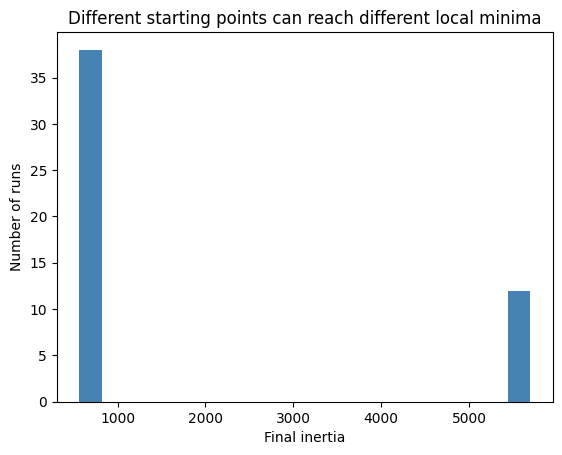

In [13]:
final_inertias = np.array([kmeans(X, 3, seed=s)[2][-1] for s in range(50)])
unique_values = np.unique(np.round(final_inertias, 2))

print("Distinct final inertia values across 50 starts:", unique_values)
print(f"Best: {final_inertias.min():.2f}, worst: {final_inertias.max():.2f}")
print(f"Runs that reached the best value: {np.sum(np.isclose(final_inertias, final_inertias.min(), atol=0.01))} / 50")

plt.hist(final_inertias, bins=20, color='steelblue')
plt.xlabel('Final inertia'); plt.ylabel('Number of runs')
plt.title('Different starting points can reach different local minima')
plt.show()

### Choosing k

The inertia always decreases as k grows (more centers can only fit better), so we cannot just pick the k with the lowest J. Two common tools:

- **Elbow method:** plot J against k and look for the point where the improvement slows sharply.
- **Silhouette score:** measures how close each point is to its own cluster compared with the nearest other cluster. It ranges from −1 to 1, and higher is better.

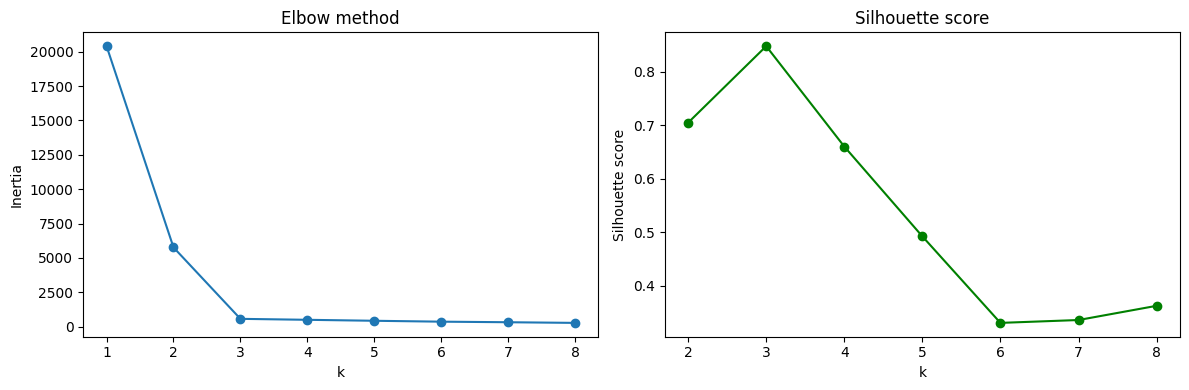

k with the highest silhouette score: 3


In [14]:
ks = range(1, 9)
inertia_by_k = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sil_by_k = [silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X))
            for k in range(2, 9)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia_by_k, 'o-')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia'); axes[0].set_title('Elbow method')
axes[1].plot(range(2, 9), sil_by_k, 'o-', color='green')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette score'); axes[1].set_title('Silhouette score')
plt.tight_layout()
plt.show()

print("k with the highest silhouette score:", 2 + int(np.argmax(sil_by_k)))

### A limitation of K-means

K-means assigns each point to the nearest center, so its clusters are always convex regions (separated by straight lines). It works well for round, similarly sized blobs, but fails when the true clusters have a different shape. Here is a two-moons dataset where the "correct" clusters are curved.

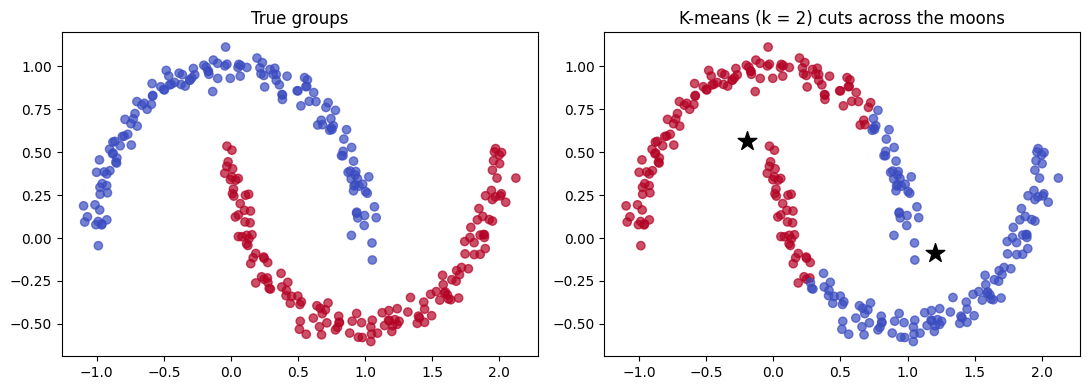

In [15]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.05, random_state=0)
km_moons = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap='coolwarm', alpha=0.7)
axes[0].set_title('True groups')
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=km_moons.labels_, cmap='coolwarm', alpha=0.7)
axes[1].scatter(*km_moons.cluster_centers_.T, c='k', marker='*', s=200)
axes[1].set_title('K-means (k = 2) cuts across the moons')
plt.tight_layout()
plt.show()

## 3.6 Support Vector Machines

For labeled data (xᵢ, yᵢ) with yᵢ ∈ {−1, +1}, a linear SVM classifies using the sign of f(x) = wᵀx + b. Among all separating hyperplanes, it picks the one with the **largest margin**. The two margin lines are wᵀx + b = ±1, and the distance between them is

margin width = 2 / ‖w‖.

**Hard-margin SVM** (data must be perfectly separable):

minimize ½‖w‖²  subject to  yᵢ(wᵀxᵢ + b) ≥ 1 for all i.

This is a convex quadratic program, so by Section 3.3.2 its solution is a global minimizer. The points that lie exactly on the margin lines are the **support vectors**, and they alone determine the solution.

We solve this problem directly with a constrained optimizer and compare with scikit-learn.

In [16]:
# Linearly separable data with labels in {-1, +1}
Xs, ys = make_blobs(n_samples=40, centers=[[-2, -2], [2, 2]], cluster_std=0.8, random_state=0)
ys = 2 * ys - 1

# Solve the hard-margin primal QP: variables v = [w1, w2, b]
objective = lambda v: 0.5 * v[:2] @ v[:2]
constraint = {'type': 'ineq', 'fun': lambda v: ys * (Xs @ v[:2] + v[2]) - 1}   # y_i (w.x_i + b) - 1 >= 0

res = minimize(objective, x0=[1.0, 1.0, 0.0], constraints=[constraint], method='SLSQP')
w_hard, b_hard = res.x[:2], res.x[2]

print("Solver converged:", res.success)
print("w =", w_hard, " b =", round(b_hard, 4))
print("Margin width 2/||w|| =", round(2 / np.linalg.norm(w_hard), 4))

# Support vectors are the points sitting on the margin: y_i (w.x_i + b) = 1
functional_margin = ys * (Xs @ w_hard + b_hard)
sv_mask = np.isclose(functional_margin, 1, atol=1e-3)
print("Number of support vectors:", sv_mask.sum())

# Compare with scikit-learn (very large C approximates a hard margin)
clf_hard = SVC(kernel='linear', C=1e6).fit(Xs, ys)
print("\nscikit-learn w =", clf_hard.coef_.ravel(), " b =", clf_hard.intercept_)
print("scikit-learn number of support vectors:", len(clf_hard.support_vectors_))
print("Solutions match:", np.allclose(w_hard, clf_hard.coef_.ravel(), atol=1e-2))

Solver converged: True
w = [0.6354 0.4563]  b = -0.1321
Margin width 2/||w|| = 2.5566
Number of support vectors: 3

scikit-learn w = [0.6355 0.4561]  b = [-0.1321]
scikit-learn number of support vectors: 3
Solutions match: True


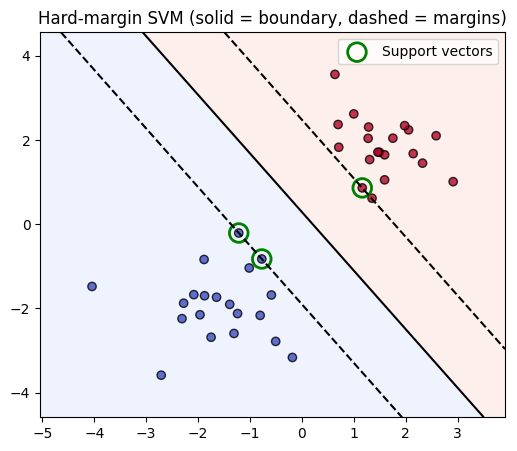

In [17]:
def plot_svm(f, X, y, sv_points, ax, title):
    """f(points) returns the decision values w.x + b (or a kernel decision function)."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    Z = f(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.15, cmap='coolwarm')
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', alpha=0.8)
    ax.scatter(sv_points[:, 0], sv_points[:, 1], s=180, facecolors='none', edgecolors='green',
               linewidths=2, label='Support vectors')
    ax.set_title(title)
    ax.legend()

fig, ax = plt.subplots(figsize=(6, 5))
plot_svm(lambda P: P @ w_hard + b_hard, Xs, ys, Xs[sv_mask], ax, 'Hard-margin SVM (solid = boundary, dashed = margins)')
plt.show()

### Soft-margin SVM

Real data usually overlaps, so no hyperplane satisfies every constraint. The **soft-margin** SVM adds slack variables ξᵢ ≥ 0 that allow violations at a cost:

minimize ½‖w‖² + C Σ ξᵢ  subject to  yᵢ(wᵀxᵢ + b) ≥ 1 − ξᵢ,  ξᵢ ≥ 0.

At the optimum, ξᵢ = max(0, 1 − yᵢ(wᵀxᵢ + b)), the **hinge loss**. So the problem is the same as minimizing ½‖w‖² + C Σ hinge(xᵢ). The parameter C controls the tradeoff: large C punishes violations heavily (narrow margin, fits the training data closely), and small C tolerates violations (wide margin, smoother boundary).

In [18]:
# Overlapping data
Xo, yo = make_blobs(n_samples=60, centers=[[-1.5, -1.5], [1.5, 1.5]], cluster_std=1.4, random_state=1)
yo = 2 * yo - 1
n = len(yo)

def soft_margin_svm(X, y, C):
    """Solve the soft-margin primal QP. Variables: [w1, w2, b, xi_1, ..., xi_n]."""
    n = len(y)
    obj = lambda v: 0.5 * v[:2] @ v[:2] + C * np.sum(v[3:])
    cons = {'type': 'ineq', 'fun': lambda v: y * (X @ v[:2] + v[2]) - 1 + v[3:]}
    bounds = [(None, None)] * 3 + [(0, None)] * n
    v0 = np.concatenate(([0.0, 0.0, 0.0], np.ones(n)))
    res = minimize(obj, v0, constraints=[cons], bounds=bounds, method='SLSQP', options={'maxiter': 500})
    return res.x[:2], res.x[2], res.x[3:], res

C = 1.0
w_soft, b_soft, xi, res = soft_margin_svm(Xo, yo, C)

print("Solver converged:", res.success)
print("My solution:      w =", w_soft, " b =", round(b_soft, 4))

clf_soft = SVC(kernel='linear', C=C).fit(Xo, yo)
print("scikit-learn:     w =", clf_soft.coef_.ravel(), " b =", clf_soft.intercept_)
print("Solutions match:", np.allclose(w_soft, clf_soft.coef_.ravel(), atol=1e-2))

# Check that the slack equals the hinge loss at the optimum
hinge = np.maximum(0, 1 - yo * (Xo @ w_soft + b_soft))
print("\nSlack equals hinge loss:", np.allclose(xi, hinge, atol=1e-3))
print("Points inside the margin or misclassified (xi > 0):", np.sum(hinge > 1e-3))
print("Training accuracy:", np.mean(np.sign(Xo @ w_soft + b_soft) == yo))

Solver converged: True
My solution:      w = [1.3771 0.9949]  b = -0.3498
scikit-learn:     w = [1.3771 0.995 ]  b = [-0.3498]
Solutions match: True

Slack equals hinge loss: True
Points inside the margin or misclassified (xi > 0): 5
Training accuracy: 0.9666666666666667


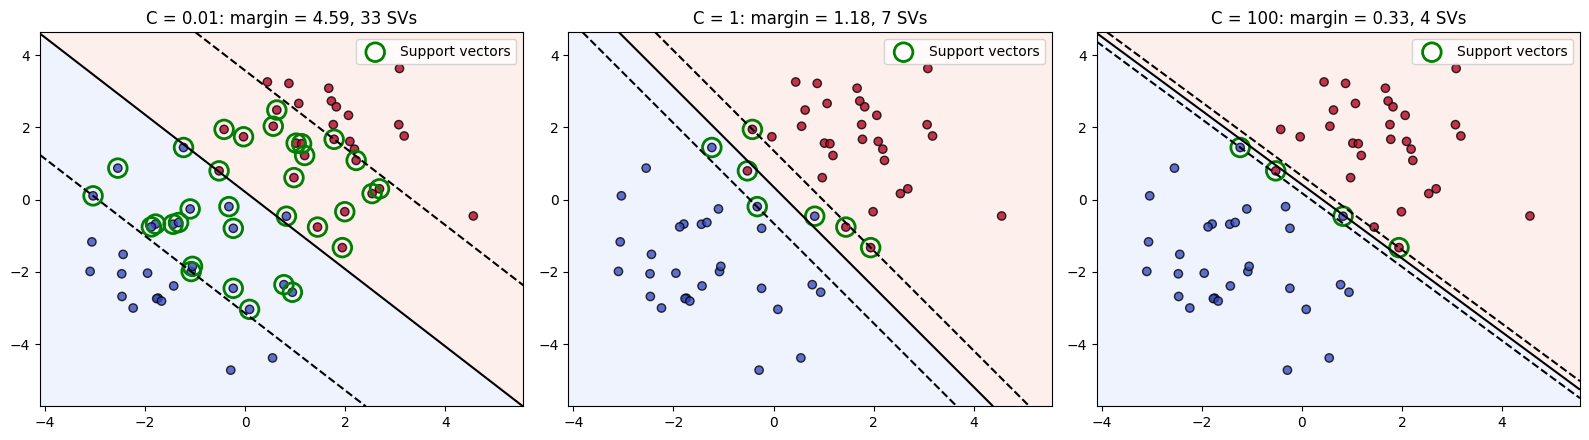

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, C_val in zip(axes, [0.01, 1, 100]):
    clf = SVC(kernel='linear', C=C_val).fit(Xo, yo)
    width = 2 / np.linalg.norm(clf.coef_)
    plot_svm(clf.decision_function, Xo, yo, clf.support_vectors_, ax,
             f'C = {C_val}: margin = {width:.2f}, {len(clf.support_vectors_)} SVs')
plt.tight_layout()
plt.show()

### Nonlinear boundaries and the kernel trick

When the classes are not linearly separable in the original space (for example, one class surrounds the other), a linear SVM fails. The **dual** formulation of the SVM depends on the data only through inner products xᵢᵀxⱼ, and the decision function is

f(x) = Σᵢ αᵢ yᵢ K(xᵢ, x) + b,

where αᵢ > 0 only for support vectors. Replacing the inner product with a **kernel** K(x, x') corresponds to working in a higher-dimensional feature space without computing it. We use the RBF kernel K(x, x') = exp(−γ‖x − x'‖²).

Linear SVM training accuracy: 0.625
RBF SVM training accuracy:    1.0

Manual dual decision function matches scikit-learn: True


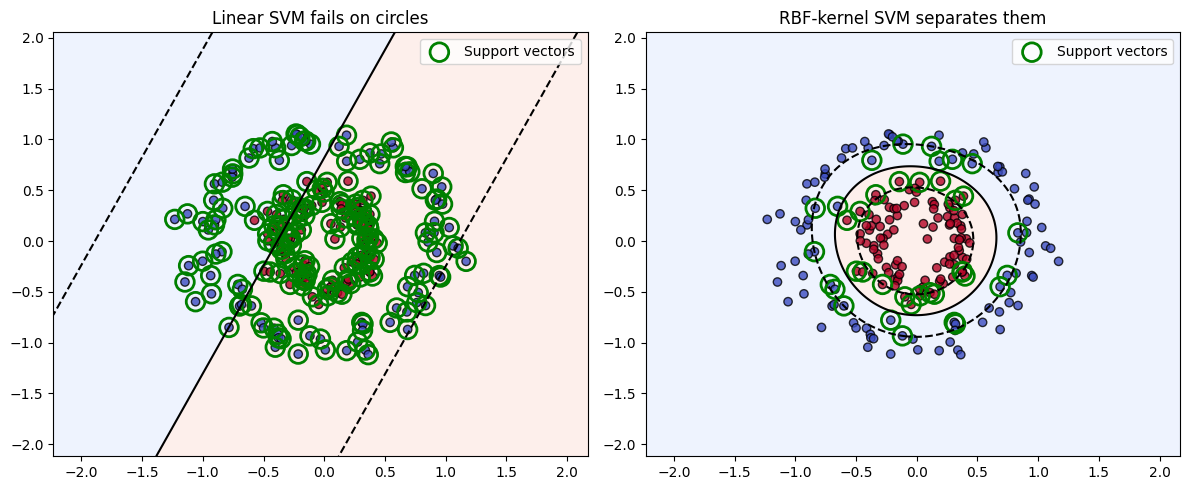

In [20]:
Xc, yc = make_circles(n_samples=200, factor=0.4, noise=0.1, random_state=0)
yc = 2 * yc - 1

clf_lin = SVC(kernel='linear', C=1).fit(Xc, yc)
clf_rbf = SVC(kernel='rbf', gamma=1.0, C=1).fit(Xc, yc)

print("Linear SVM training accuracy:", clf_lin.score(Xc, yc))
print("RBF SVM training accuracy:   ", clf_rbf.score(Xc, yc))

# Verify the dual formula f(x) = sum_i (alpha_i y_i) K(x_i, x) + b by hand
K = rbf_kernel(clf_rbf.support_vectors_, Xc, gamma=1.0)       # shape (n_SV, n_points)
f_manual = clf_rbf.dual_coef_ @ K + clf_rbf.intercept_         # dual_coef_ holds alpha_i * y_i
print("\nManual dual decision function matches scikit-learn:",
      np.allclose(f_manual.ravel(), clf_rbf.decision_function(Xc)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_svm(clf_lin.decision_function, Xc, yc, clf_lin.support_vectors_, axes[0], 'Linear SVM fails on circles')
plot_svm(clf_rbf.decision_function, Xc, yc, clf_rbf.support_vectors_, axes[1], 'RBF-kernel SVM separates them')
plt.tight_layout()
plt.show()